In [30]:
import solarpy
import pvlib
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import numpy as np

# Measurement data

In [33]:
dmi_data, dmi_meta = solarpy.iotools.get_dmi_metobs(station = '06056',
                                          start='2025-11-02',
                                          end='2026-11-02',
                                          parameters = ['ghi'])

#### Find extra-terrestrial radiation and solar position

In [34]:
solarposition = pvlib.solarposition.get_solarposition(
    time=dmi_data.index, latitude=dmi_meta['latitude'], longitude=dmi_meta['longitude'],
)

dmi_data['solar_zenith'] = solarposition['apparent_zenith']
dmi_data['solar_azimuth'] = solarposition['azimuth']

dni_extra = pvlib.irradiance.get_extra_radiation(dmi_data.index)
cos_sza = np.cos(np.deg2rad(solarposition["apparent_zenith"])).clip(lower=0)
dmi_data['ghi_extra'] = dni_extra * cos_sza

print(dmi_data.head())


parameterId                ghi  solar_zenith  solar_azimuth  ghi_extra
timestamp                                                             
2025-11-02 00:00:00+00:00  0.0    137.245234      18.361477        0.0
2025-11-02 00:10:00+00:00  0.0    136.771709      21.838362        0.0
2025-11-02 00:20:00+00:00  0.0    136.220853      25.257965        0.0
2025-11-02 00:30:00+00:00  0.0    135.595963      28.614455        0.0
2025-11-02 00:40:00+00:00  0.0    134.900595      31.903255        0.0


#### Check BSRN limits

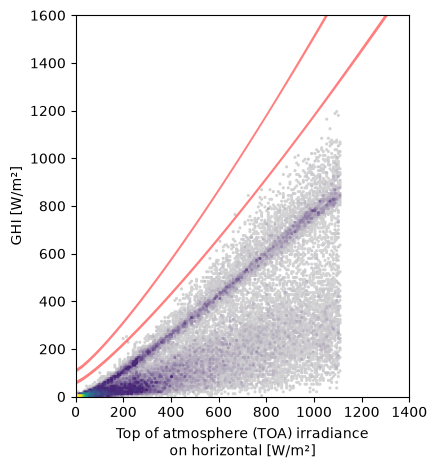

In [35]:
fig, axes = solarpy.plotting.plot_bsrn_limits(
    irradiance=dmi_data['ghi'],
    component="ghi",
    ghi_extra= dmi_data['ghi_extra'],
)
fig.tight_layout()

#### Checking shading

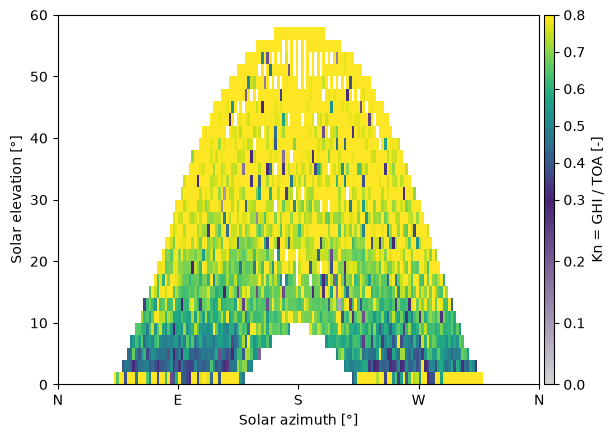

In [36]:
fig, ax = solarpy.plotting.plot_shading_heatmap(
    value=dmi_data["ghi"] / dmi_data["ghi_extra"],
    solar_azimuth=dmi_data["solar_azimuth"],
    solar_elevation=90-dmi_data["solar_zenith"],
    azimuth_bin_size = 2,
    elevation_bin_size = 2,
    cmap=solarpy.plotting.two_part_colormap(),
    norm=TwoSlopeNorm(vmin=0, vcenter=0.3, vmax=0.8),
    colorbar_label="Kn = GHI / TOA [-]",
)

#### Checking intraday heatmap

C:\Users\karla\AppData\Local\Temp\ipykernel_41000\1717822294.py:17: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  pd.date_range(dmi_data.index.min(), dmi_data.index.max(), freq="1d"),


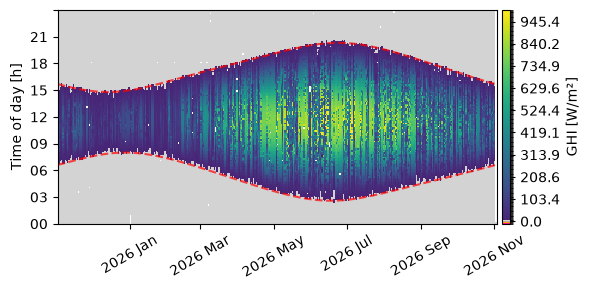

In [37]:

# Load custom colormap and norm
cmap, norm = solarpy.plotting.irradiance_colormap_and_norm(vmax=1000)

fig, ax = plt.subplots(figsize=(6, 3))

_ = solarpy.plotting.plot_intraday_heatmap(
    time=dmi_data.index,
    values=dmi_data["ghi"],
    cmap=cmap,
    norm=norm,
    colorbar_label="GHI [W/m²]",
    ax=ax,  # pass in existing axes
)

# Overlay sunrise and sunset times
sun_rise_set = pvlib.solarposition.sun_rise_set_transit_spa(
    pd.date_range(dmi_data.index.min(), dmi_data.index.max(), freq="1d"),
    dmi_meta["latitude"],
    dmi_meta["longitude"],
)

sunrise = (
    sun_rise_set["sunrise"] - sun_rise_set["sunrise"].index.normalize()
).dt.total_seconds() / 3600

sunset = (
    sun_rise_set["sunset"] - sun_rise_set["sunset"].index.normalize()
).dt.total_seconds() / 3600


ax.plot(sunrise, c="r", linestyle="dashed", lw=1.5, alpha=0.7)
ax.plot(sunset, c="r", linestyle="dashed", lw=1.5, alpha=0.7)

fig.tight_layout()

#### Resampling in hourly resolution

In [40]:
dmi_data = dmi_data.resample("1h", closed="right", label="right").mean()
print(dmi_data.head())

parameterId                ghi  solar_zenith  solar_azimuth  ghi_extra
timestamp                                                             
2025-11-02 00:00:00+00:00  0.0    135.812141      26.849423        0.0
2025-11-02 01:00:00+00:00  0.0    130.929844      45.695284        0.0
2025-11-02 02:00:00+00:00  0.0    124.263310      62.010276        0.0
2025-11-02 03:00:00+00:00  0.0    116.546012      76.292918        0.0
2025-11-02 04:00:00+00:00  0.0    108.351327      89.270509        0.0
